## 1. Imports and environment check

We use TensorFlow/Keras for the LSTM and attention layers, NumPy/Pandas for data handling, and Matplotlib for plots.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.layers import Input, LSTM, Dense, Attention, Concatenate, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import MinMaxScaler

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Available devices:", tf.config.list_physical_devices())


TensorFlow: 2.21.0
NumPy: 2.5.4
Pandas: 3.1.1
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Seq2Seq: the basic idea

A **Sequence-to-Sequence (Seq2Seq)** model maps one sequence to another sequence.

For our forecasting task:
- **Input sequence:** demand from the previous 30 days.
- **Output sequence:** predicted demand for the next 7 days.

The architecture has two main parts:

- **Encoder:** reads the input sequence and creates hidden representations.
- **Decoder:** uses the encoded information to generate the output sequence.

A traditional encoder–decoder can pass a single final context representation to the decoder. For long inputs, compressing everything into one vector can lose useful information. **Attention** addresses this by allowing the decoder to look back at all encoder time-step outputs and assign different weights to them.


## 3. Create a retail-demand-style dataset

We generate daily demand with trend, weekly seasonality, yearly seasonality, and random noise. The data is synthetic and generated locally, so no CSV download is required.

,day,sales
0,2023-01-01,102.483571
1,2023-01-02,109.015497
2,2023-01-03,115.587167
3,2023-01-04,113.795908
4,2023-01-05,94.921072


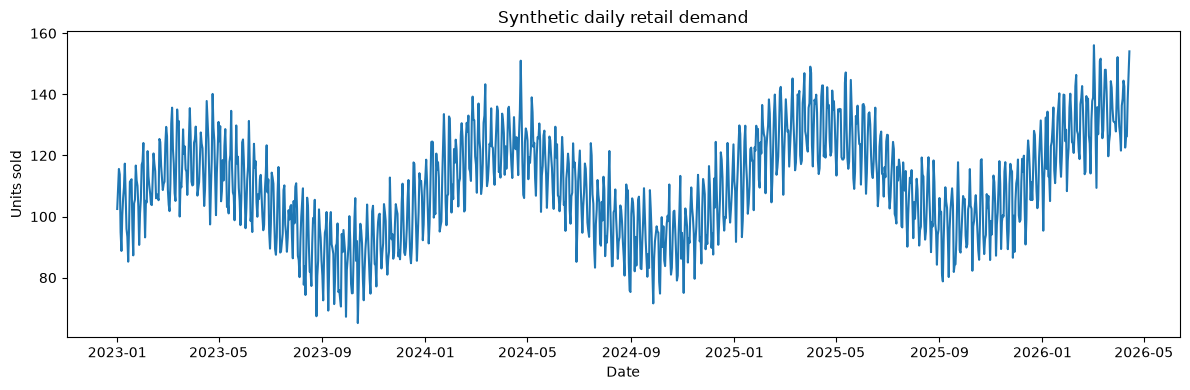

In [2]:
# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

n_days = 1200
days = np.arange(n_days)

trend = 0.015 * days
weekly_pattern = 12 * np.sin(2 * np.pi * days / 7)
yearly_pattern = 18 * np.sin(2 * np.pi * days / 365)
noise = np.random.normal(0, 5, n_days)

sales = 100 + trend + weekly_pattern + yearly_pattern + noise
sales = np.maximum(sales, 1)  # demand cannot be negative

sales_df = pd.DataFrame({
    "day": pd.date_range("2023-01-01", periods=n_days, freq="D"),
    "sales": sales
})

display(sales_df.head())
plt.figure(figsize=(12, 4))
plt.plot(sales_df["day"], sales_df["sales"])
plt.title("Synthetic daily retail demand")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.tight_layout()
plt.show()


## 4. Prepare input and target sequences

We use a sliding window:
- `LOOKBACK = 30`: 30 previous days are given to the model.
- `HORIZON = 7`: the model predicts the next 7 days.

We split chronologically (not randomly) to avoid training on future observations and evaluating on the past.

In [3]:
LOOKBACK = 30
HORIZON = 7

values = sales.astype("float32").reshape(-1, 1)

# Chronological split: first 70% train, next 15% validation, final 15% test
train_end = int(len(values) * 0.70)
val_end = int(len(values) * 0.85)

# Fit scaler only on training data to avoid leakage
scaler = MinMaxScaler()
scaler.fit(values[:train_end])
scaled_values = scaler.transform(values)

def make_windows(series, lookback, horizon, start_index, end_index):
    X, y = [], []
    first_target = max(start_index, lookback)
    for target_start in range(first_target, end_index - horizon + 1):
        X.append(series[target_start - lookback:target_start])
        y.append(series[target_start:target_start + horizon])
    return np.array(X), np.array(y)

X_train, y_train = make_windows(scaled_values, LOOKBACK, HORIZON, 0, train_end)
X_val, y_val = make_windows(scaled_values, LOOKBACK, HORIZON, train_end, val_end)
X_test, y_test = make_windows(scaled_values, LOOKBACK, HORIZON, val_end, len(values))

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)


X_train: (804, 30, 1) y_train: (804, 7, 1)
X_val:   (174, 30, 1) y_val:   (174, 7, 1)
X_test:  (174, 30, 1) y_test:  (174, 7, 1)


### Understand the shapes

A model input has shape `(number_of_examples, 30, 1)`:
- `number_of_examples`: how many training windows exist.
- `30`: 30 time steps.
- `1`: one feature (daily sales).

A target has shape `(number_of_examples, 7, 1)` because each example predicts 7 future time steps.

## 5. Build the Seq2Seq model with attention

### Encoder
`LSTM(..., return_sequences=True, return_state=True)` returns:
- `encoder_outputs`: an output vector for every input time step.
- `state_h`: final hidden state.
- `state_c`: final cell state.

### Decoder
We repeat the final encoder hidden state for 7 forecast steps and use it to initialize the decoder LSTM.

### Attention
`Attention()([decoder_outputs, encoder_outputs])` uses decoder outputs as **queries** and encoder outputs as **values/keys**. It produces a context vector for each forecast step.

We concatenate the decoder output and attention context, then use a Dense layer to predict sales at each future step.

In [4]:
# Encoder input: 30 days, one feature
encoder_input = Input(shape=(LOOKBACK, 1), name="encoder_input")

encoder_outputs, state_h, state_c = LSTM(
    64,
    return_sequences=True,
    return_state=True,
    name="encoder_lstm"
)(encoder_input)

# Decoder receives a repeated summary vector for the 7 forecast steps
decoder_seed = RepeatVector(HORIZON, name="repeat_encoder_state")(state_h)

decoder_outputs = LSTM(
    64,
    return_sequences=True,
    name="decoder_lstm"
)(decoder_seed, initial_state=[state_h, state_c])

# Attention: each decoder time step can focus on encoder time steps
attention_layer = Attention(name="attention")
context = attention_layer([decoder_outputs, encoder_outputs])

combined = Concatenate(axis=-1, name="combine_context")(
    [decoder_outputs, context]
)

forecast = Dense(1, name="sales_forecast")(combined)

model = Model(encoder_input, forecast, name="Retail_Seq2Seq_Attention")
model.compile(optimizer="adam", loss="mse", metrics=["mae"])

model.summary()


Model: "Retail_Seq2Seq_Attention"

┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)       ┃ Output Shape     ┃   Param # ┃ Connected to     ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━┩
│ encoder_input      │ (None, 30, 1)    │         0 │ -                │
│ (InputLayer)       │                  │           │                  │
├────────────────────┼──────────────────┼───────────┼──────────────────┤
│ encoder_lstm       │ [(None, 30, 64), │    16,896 │ encoder_input[0… │
│ (LSTM)             │ (None, 64),      │           │                  │
│                    │ (None, 64)]      │           │                  │
├────────────────────┼──────────────────┼───────────┼──────────────────┤
│ repeat_encoder_st… │ (None, 7, 64)    │         0 │ encoder_lstm[0]… │
│ (RepeatVector)     │                  │           │                  │
├────────────────────┼──────────────────┼───────────┼──────────────────┤
│ decoder_lstm       │ (None, 7, 64)    │    33,024 │ repeat_encoder_… │
│ (LSTM)             │                  │           │ encoder_lstm[0]… │
│                    │                  │           │ encoder_lstm[0]… │
├────────────────────┼──────────────────┼───────────┼──────────────────┤
│ attention          │ (None, 7, 64)    │         0 │ decoder_lstm[0]… │
│ (Attention)        │                  │           │ encoder_lstm[0]… │
├────────────────────┼──────────────────┼───────────┼──────────────────┤
│ combine_context    │ (None, 7, 128)   │         0 │ decoder_lstm[0]… │
│ (Concatenate)      │                  │           │ attention[0][0]  │
├────────────────────┼──────────────────┼───────────┼──────────────────┤
│ sales_forecast     │ (None, 7, 1)     │       129 │ combine_context… │
│ (Dense)            │                  │           │                  │
└────────────────────┴──────────────────┴───────────┴──────────────────┘

 Total params: 50,049 (195.50 KB)

 Trainable params: 50,049 (195.50 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the model

We use early stopping to restore the weights from the epoch with the lowest validation loss.

Epoch 1/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 7s 63ms/step - loss: 0.0729 - mae: 0.2019 - val_loss: 0.0169 - val_mae: 0.1057
Epoch 2/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0169 - mae: 0.1062 - val_loss: 0.0131 - val_mae: 0.0960
Epoch 3/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0152 - mae: 0.1013 - val_loss: 0.0136 - val_mae: 0.0973
Epoch 4/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0146 - mae: 0.0995 - val_loss: 0.0137 - val_mae: 0.0975
Epoch 5/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0143 - mae: 0.0985 - val_loss: 0.0133 - val_mae: 0.0967
Epoch 6/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0141 - mae: 0.0981 - val_loss: 0.0132 - val_mae: 0.0965
Epoch 7/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0140 - mae: 0.0979 - val_loss: 0.0130 - val_mae: 0.0961
Epoch 8/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0139 - mae: 0.0976 - val_loss: 0.0129 - val_mae: 0.0956
Epoch 9/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.013

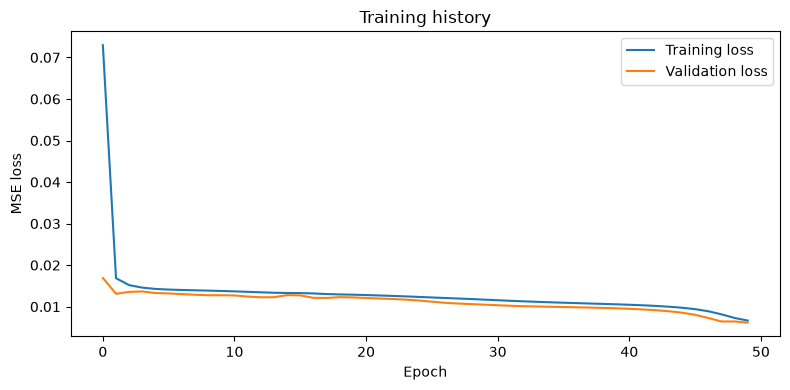

In [5]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Training history")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Evaluate on the test set

We invert the MinMax scaling so the metrics are reported in the original sales units.

In [6]:
pred_scaled = model.predict(X_test, verbose=0)

y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1)).reshape(y_test.shape)
pred_actual = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).reshape(pred_scaled.shape)

mae = np.mean(np.abs(y_test_actual - pred_actual))
rmse = np.sqrt(np.mean((y_test_actual - pred_actual) ** 2))

print(f"Test MAE:  {mae:.2f} units")
print(f"Test RMSE: {rmse:.2f} units")


Test MAE:  5.41 units
Test RMSE: 6.78 units


## 8. Visualize one 7-day forecast

The chart compares the actual next 7 days with the model's forecast for one test example.

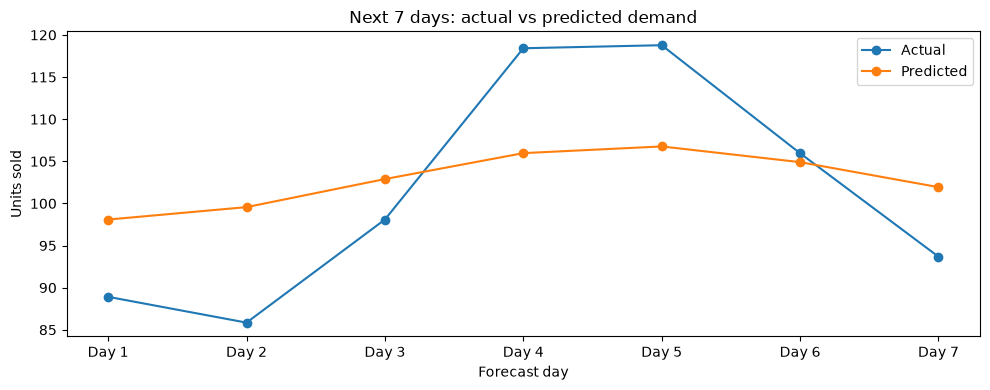

In [7]:
sample_index = 0

plt.figure(figsize=(10, 4))
plt.plot(range(HORIZON), y_test_actual[sample_index, :, 0],
         marker="o", label="Actual")
plt.plot(range(HORIZON), pred_actual[sample_index, :, 0],
         marker="o", label="Predicted")
plt.title("Next 7 days: actual vs predicted demand")
plt.xlabel("Forecast day")
plt.ylabel("Units sold")
plt.xticks(range(HORIZON), [f"Day {i+1}" for i in range(HORIZON)])
plt.legend()
plt.tight_layout()
plt.show()


## 9. Inspect attention weights

To visualize attention, we create a second model that outputs the attention layer's scores. Each row corresponds to one decoder/forecast step; each column corresponds to one encoder/input day.

A larger weight means that the decoder step placed more attention on that input time step. Attention weights are useful for inspecting the model, but they should not automatically be treated as a complete explanation of why a prediction was made.

In [10]:
# ==========================================
# DAY 10: ATTENTION WEIGHT VISUALIZATION
# ==========================================

# Create a separate model to extract attention scores
# attention_scores must have been created in Cell 8:
#
# context, attention_scores = attention_layer(
#     [decoder_outputs, encoder_outputs],
#     return_attention_scores=True
# )

attention_score_model = Model(
    inputs=encoder_input,
    outputs=attention_scores
)

# Select one test sample
sample_index = 0

# Extract attention weights
scores = attention_score_model.predict(
    X_test[sample_index:sample_index + 1],
    verbose=0
)[0]

# Display attention heatmap
plt.figure(figsize=(12, 5))

plt.imshow(
    scores,
    aspect="auto",
    cmap="viridis",
    interpolation="nearest"
)

plt.colorbar(label="Attention weight")

plt.xlabel("Input day (oldest to most recent)")
plt.ylabel("Forecast step")

plt.xticks(range(LOOKBACK))
plt.yticks(
    range(HORIZON),
    [f"Day {i+1}" for i in range(HORIZON)]
)

plt.title("Seq2Seq Attention Weights")

plt.tight_layout()
plt.show()

# Display attention score dimensions
print("Attention score shape:", scores.shape)
print("Number of input time steps:", LOOKBACK)
print("Number of forecast steps:", HORIZON)

ValueError: Output with path `` is not connected to `inputs`

## 10. Save the model in RetailMind-AI

This saves the model to the project's `Models` folder. Since this notebook is inside `Notebooks`, `../Models` points to the project-level folder.

If your folder is named `models` with a lowercase `m`, change the path accordingly.

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
MODELS_DIR = PROJECT_ROOT / "Models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS_DIR / "retail_seq2seq_attention.keras"
model.save(MODEL_PATH)

print("Model saved:", MODEL_PATH.resolve())


## 11. Key concepts — revision

| Term | Meaning |
|---|---|
| Seq2Seq | A model that maps an input sequence to an output sequence |
| Encoder | Reads the input sequence and creates representations |
| Decoder | Generates the output sequence |
| Hidden state | Carries information through an RNN/LSTM sequence |
| Cell state | LSTM memory pathway |
| Context vector | Information passed from encoder to decoder |
| Attention | Lets each decoder step weigh encoder time-step outputs |
| Query | Decoder representation asking what information is relevant |
| Key/Value | Encoder representations that the query attends to |

### Seq2Seq without attention vs with attention

- **Without attention:** decoder relies mainly on a compressed encoder representation.
- **With attention:** each decoder step can access the encoder's sequence of outputs and form its own context.

### Important limitation
This notebook uses a univariate synthetic time series. A production retail forecasting model may need product/store identifiers, promotions, prices, holidays, stock-outs, and other features. It should also be evaluated with time-based validation and compared against simple baselines.

## 12. Day 10 completion checklist

- [ ] I can explain Encoder and Decoder.
- [ ] I understand why a single context vector can be a bottleneck.
- [ ] I can explain Query, Key, Value, and attention weights.
- [ ] I trained a Seq2Seq model with attention.
- [ ] I evaluated its predictions on a chronological test set.
- [ ] I visualized attention weights.
- [ ] I saved the model under `Models/retail_seq2seq_attention.keras`.

**Suggested Git commit message:** `Add Day 10 Seq2Seq with Attention for retail demand forecasting`
